##### Copyright 2026 The Contributors

Licensed under the Apache License, Version 2.0 (the "License");
you may not use this file except in compliance with the License.
See the LICENSE file in the repository root.


# 04 — Model training (two-stage hurdle)

This mirrors the production `TwoStageHurdleModel` (AI-ACF-ML-Prediction,
`api/services/two_stage_model.py`), not a simplified rewrite.

**Stage 1 (gate):** `XGBClassifier` → P(any case next month). Class-imbalance
is handled with `scale_pos_weight` since positives are rare (see notebook `02`).

**Calibrate:** an `IsotonicRegression` calibrator is fit on the Stage-1
*validation* fold to correct gate probabilities distorted by the
`scale_pos_weight` reweighting.

**Stage 2 (count):** `XGBRegressor` with a Poisson objective, trained **only
on hexagon-months with `target_cases > 0`** → E[cases | cases > 0]. Count
data is Poisson-distributed (non-negative integers, variance grows with the
mean), so a plain squared-error regressor would be miscalibrated here.

**Combine:** `expected_cases = calibrated_gate_prob × count_pred` --
multiplicative and continuous, not a hard threshold cutoff. A hard threshold
would zero out borderline hexagons right at the gate boundary and discard
exactly the probability information the calibration step just fixed.

A single-stage Poisson (no gate) is also trained as a baseline so you can see
whether the two-stage split is actually earning its complexity on your data.

## Prerequisites
- `artifacts/train.csv` and `feature_cols.csv` from notebook `03`

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 60)
print("ROOT =", ROOT)


ROOT = /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks


In [2]:
from utils import ARTIFACTS_DIR, load_data
from pipeline.training import train_two_stage_models, save_models, predict_two_stage

train_df = load_data(ARTIFACTS_DIR / "train.csv")
feature_cols = pd.read_csv(ARTIFACTS_DIR / "feature_cols.csv")["feature"].tolist()
print(f"Training on {len(train_df)} rows, {len(feature_cols)} features")
print(f"Positive rate in training data: {train_df['has_any_cases'].mean()*100:.1f}%")


Training on 5100 rows, 25 features
Positive rate in training data: 63.3%


In [3]:
bundle = train_two_stage_models(train_df, feature_cols, random_state=42)
save_models(bundle)
print("\nValidation metrics captured during training:")
bundle["metrics"]


INFO | Stage 1 gate val AUC: 0.7361 | AP: 0.8046


INFO | Gate calibrated AP: 0.8078 (raw AP: 0.8046)


INFO | Stage 2 non-zero val RMSE: 0.9871620964865961


INFO | Models saved to /Users/froncort.ai/Desktop/Froncort/ai-acf-ml-notebooks/artifacts/models



Validation metrics captured during training:


{'gate_auc': 0.7361115710004801,
 'gate_ap': 0.8046491917375204,
 'calibrated_ap': 0.8078324644926853,
 'stage2_rmse_nz': 0.9871620964865961}

## Feature importance

Which engineered features is each stage actually relying on? Compare Stage 1
(what predicts *any* case) against Stage 2 (what predicts *how many*, given
there is at least one) -- they often differ, which is exactly why the
two-stage split can help.


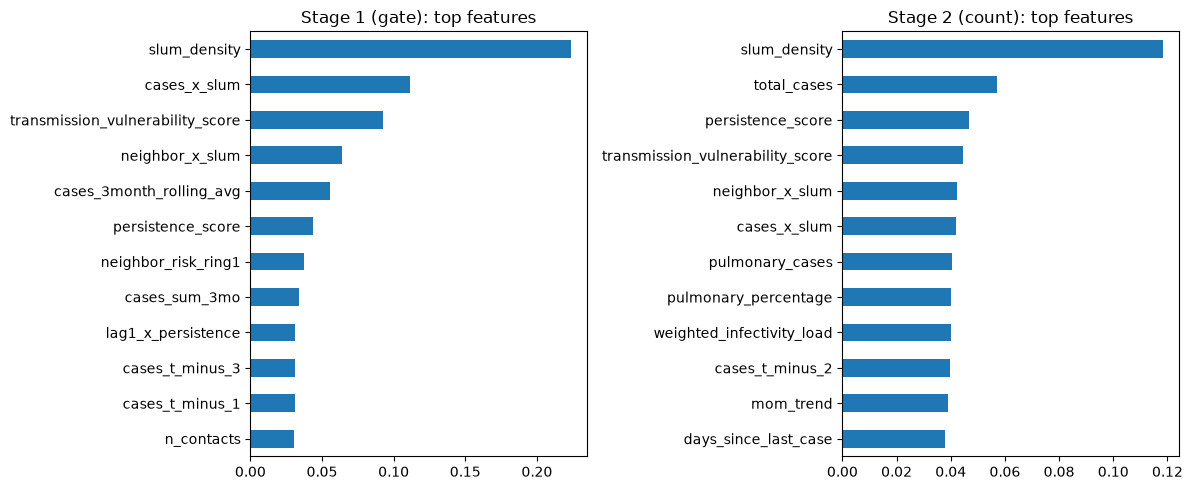

In [4]:
def plot_importance(model, feature_cols, title, ax):
    importances = pd.Series(model.feature_importances_, index=feature_cols).sort_values(ascending=True).tail(12)
    importances.plot(kind="barh", ax=ax)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_importance(bundle["stage1"], feature_cols, "Stage 1 (gate): top features", axes[0])
plot_importance(bundle["stage2"], feature_cols, "Stage 2 (count): top features", axes[1])
plt.tight_layout()
plt.show()


## Sanity check on a small sample

Manually inspect a handful of predictions before moving to formal evaluation
in notebook `05` -- eyeballing raw numbers catches obviously broken output
(e.g. all-zero predictions, or gate probabilities that never move) faster
than any metric.


In [5]:
sample = train_df[feature_cols].fillna(0).head(10)
pred, gate = predict_two_stage(bundle["stage1"], bundle["stage2"], sample, bundle["calibrator"])
pd.DataFrame({
    "actual_target_cases": train_df["target_cases"].head(10).values,
    "predicted_cases": pred.round(2),
    "gate_probability": gate.round(3),
})


,actual_target_cases,predicted_cases,gate_probability
0,3,1.83,0.837
1,0,0.39,0.314
2,1,1.19,0.720
3,7,1.77,0.644
4,1,1.48,0.821
5,2,1.15,0.720
6,2,2.12,0.883
7,0,1.98,0.883
8,2,1.80,0.821
9,1,0.88,0.625


## Where the models are saved

`save_models` writes to `artifacts/models/`: `stage1_gate.joblib`,
`stage2_poisson.joblib`, `calibrator.joblib` (isotonic gate calibrator),
`single_poisson.joblib` (baseline), and `metadata.joblib` (feature list +
training metrics). Notebook `05` and `06` load this bundle with
`pipeline.training.load_models()`.